# **Lab 7(A) - Laplacian Filter**

In [2]:
import cv2
import numpy as np

from IPython.display import Image, display
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)

# OpenCV loads color as BGR, matplotlib expects RGB
def show(im):
    return cv2.cvtColor(im, cv2.COLOR_BGR2RGB)



## Apply Laplacian Filter on Image to get Sharp Image

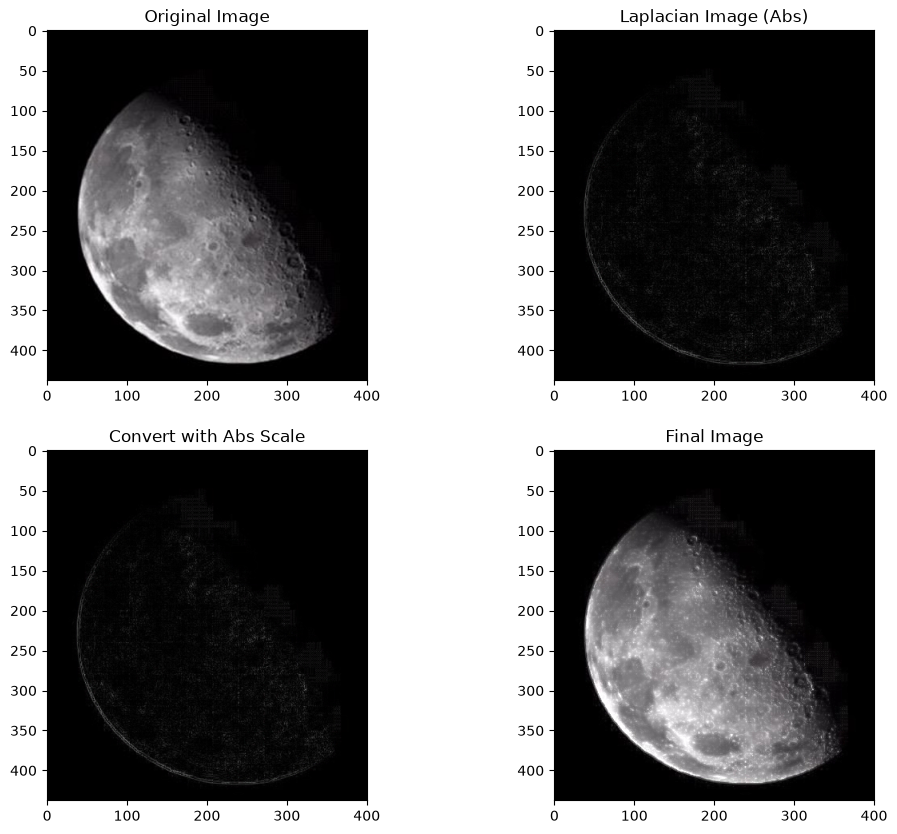

In [3]:
# ================ ( Laplacian Filter ) ===================

# 0. Image file path
imgFile = "moon.jpg"

# 1. Load image in COLOR (no 0 flag)
img = cv2.imread(imgFile)

# 2. Manually define the Laplacian kernel
manual_kernel = np.array([
    [0,  1,  0],
    [1, -4,  1],
    [0,  1,  0]
], dtype=np.float32)

# Alternative kernel (diagonal edges too):
# manual_kernel = np.array([
#     [1,  1,  1],
#     [1, -8,  1],
#     [1,  1,  1]
# ], dtype=np.float32)

# 3. filter2D applies the kernel to each color channel (B, G, R)
laplacian_manual = cv2.filter2D(img, cv2.CV_64F, manual_kernel)

# 4. Absolute value and back to 8-bit
laplacian_abs = cv2.convertScaleAbs(laplacian_manual)

# cv2.add saturates at 255 (a plain + would wrap around)
finalImage = cv2.add(img, laplacian_abs)

# 5. Display
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(show(img)), plt.title('Original Image')
plt.subplot(222), plt.imshow(show(laplacian_abs)), plt.title('Laplacian Image (Abs)')
plt.subplot(223), plt.imshow(show(laplacian_abs)), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(show(finalImage)), plt.title('Final Image')
plt.show()

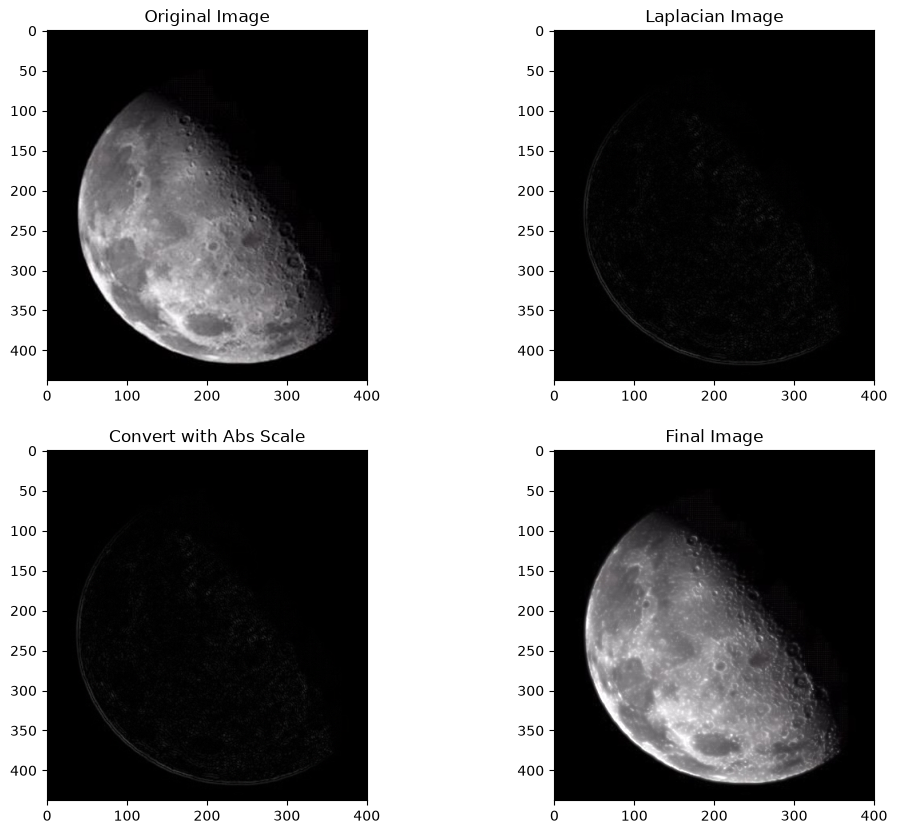

In [4]:
# ================== ( Laplacian Filter ) ===============

# 1. Optional: Gaussian blur to reduce noise
blurred = cv2.GaussianBlur(img, (3, 3), 0)

# 2. Laplacian (CV_64F keeps negative values)
laplacian = cv2.Laplacian(blurred, cv2.CV_64F)

# 3. Back to 8-bit
laplacian_8bit = cv2.convertScaleAbs(laplacian)

# 4. Add Laplacian and original image
finalImage2 = cv2.add(img, laplacian_8bit)

# 5. Display
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(show(img)), plt.title('Original Image')
plt.subplot(222), plt.imshow(show(laplacian_8bit)), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(show(laplacian_8bit)), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(show(finalImage2)), plt.title('Final Image')
plt.show()




##